# Multi-Agent Industrial Analytics — Build Progress

An **orchestrator + three specialist agents** (Problem.md §1) over a thermal-power-plant
dataset, built on LangGraph. The orchestrator plans and delegates; each specialist writes
its own expert SQL / Cypher / Python in its **own isolated context**.

```
                    orchestrator   (plans · delegates · sequences · answers)
                         │
   ┌─────────────────────┼─────────────────────┐
   ▼                     ▼                     ▼
graph_agent           sql_agent            coder_agent
  Neo4j               PostgreSQL        sandboxed Python
```

Design: `docs/agentic_design/08` (architecture) · `09` (implementation steps).

## Setup — path, .env and tracing

In [1]:
import os, sys
from pathlib import Path

root = Path.cwd()
while not (root / "langgraph.json").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

from mas.config import load_env_file
# Exports the WHOLE .env, not just the Gemini key: LangSmith is configured purely
# through environment variables, so loading only GEMINI_API_KEY left every notebook
# run silently untraced.
load_env_file()

print("repo root  :", root)
print("gemini key :", "set" if os.getenv("GEMINI_API_KEY") else "MISSING")
print("tracing    :", os.getenv("LANGSMITH_TRACING", "off"), "->", os.getenv("LANGSMITH_PROJECT", "-"))

repo root  : D:\Sriharsha\personal\personal\multi_agent_system
gemini key : set
tracing    : true -> mas-industrial-analytics


## Progress ledger

Dynamic — it imports each module, so it reflects the real state of the tree.

In [2]:
import importlib
for label, mod in [
    ("0  Foundations (config, frozen anchor)",        "mas.config"),
    ("1  Catalog + DB layer",                          "mas.db"),
    ("2  Safety validators + executors (execution/)",      "mas.execution"),
    ("3  Artifacts + digests (data-separation)",       "mas.memory"),
    ("4  Specialist agents + expert prompts",          "mas.agents.specialists"),
    ("5  Orchestrator (supervisor over the team)",     "mas.orchestrator"),
    ("6  Golden eval harness",                         "mas.eval.golden"),
]:
    try:
        importlib.import_module(mod); print(f"[DONE]  {label}")
    except Exception as e:
        print(f"[ -- ]  {label}  ({e})")

[DONE]  0  Foundations (config, frozen anchor)
[DONE]  1  Catalog + DB layer
[DONE]  2  Safety validators + executors (execution/)


[DONE]  3  Artifacts + digests (data-separation)


C:\Users\SriharshaVelicheti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\langchain_core\utils\pydantic.py:41: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


[DONE]  4  Specialist agents + expert prompts
[DONE]  5  Orchestrator (supervisor over the team)
[DONE]  6  Golden eval harness


## Stage 0 — Foundations & the frozen anchor

One config owns time, seeds and model choice. The **frozen anchor** makes "yesterday" mean
the same instant on every run.

In [3]:
from mas.config import get_settings
s = get_settings()
print("frozen anchor :", s.anchor.isoformat())
print("window        :", s.window_start.date(), "->", s.window_end.date())
print("models        :", s.gemini_reasoning_model, "/", s.gemini_fast_model)

frozen anchor : 2026-09-07T00:00:00+00:00
window        : 2026-08-08 -> 2026-09-07
models        : gemini-3.7-flash / gemini-3.7-flash


## Stage 1 — The agent team (3 + 1)

The orchestrator holds **no database tools at all** — it only delegates. Each specialist
owns its own tools and runs its own loop.

In [4]:
import mas.orchestrator.agent as orch
from mas.agents import specialists as S

print("ORCHESTRATOR delegates to:")
for t in orch.TEAM:
    print(f"  - {t.name}({', '.join(t.args)})")

print("\nSPECIALISTS and their own tools:")
for name, tools in [("graph_agent", S.GRAPH_TOOLS), ("sql_agent", S.SQL_TOOLS),
                    ("coder_agent", S.CODER_TOOLS)]:
    print(f"  {name:<12} -> {[t.name for t in tools]}")

ORCHESTRATOR delegates to:
  - graph_agent(task)
  - sql_agent(task)
  - coder_agent(task)

SPECIALISTS and their own tools:
  graph_agent  -> ['resolve_window', 'candidate_tags', 'graph_query']
  sql_agent    -> ['explore_schema', 'resolve_window', 'tag_stats', 'sql_query']
  coder_agent  -> ['python_analysis', 'sql_query']


## Stage 2 — The safety boundary

Nothing generated reaches a driver or the sandbox until it passes a validator: `sqlglot`
for SQL, a clause denylist + READ session for Cypher, an AST allowlist for Python.

In [5]:
from mas.execution import (validate_sql, validate_cypher, validate_python,
                       SqlValidationError, CypherValidationError, PyValidationError)

print("SQL ok ->", validate_sql("SELECT ts, bearing_temp_1 FROM bfpa")[:80], "...")
for bad in ["DROP TABLE bfpa", "DELETE FROM bfpa", "SELECT pg_read_file('/etc/passwd')"]:
    try: validate_sql(bad); print("LEAK!", bad)
    except SqlValidationError as e: print("blocked ->", bad, "|", str(e)[:45])
try: validate_cypher("MATCH (n) DETACH DELETE n")
except CypherValidationError as e: print("blocked -> Cypher write |", e)
try: validate_python("import os; os.system('ls')")
except PyValidationError as e: print("blocked -> Python |", e)

SQL ok -> SELECT ts, bearing_temp_1 FROM bfpa LIMIT 10000 ...
blocked -> DROP TABLE bfpa | only SELECT queries allowed (got Drop)
blocked -> DELETE FROM bfpa | only SELECT queries allowed (got Delete)
blocked -> SELECT pg_read_file('/etc/passwd') | disallowed function: pg_read_file
blocked -> Cypher write | write clause detected (CREATE/MERGE/DELETE/SET/...)
blocked -> Python | import not allowed: os


## Stage 3 — The orchestrator graph

`create_agent` builds the loop: model → tools → model → … until it answers without calling
a tool. Here the "tools" are the three specialists, so each `tools` hop runs a whole
sub-agent.

In [6]:
from mas.orchestrator import build_agent
agent = build_agent()
print(agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	TodoListMiddleware\2eafter_model(TodoListMiddleware.after_model)
	ModelCallLimitMiddleware\2ebefore_model(ModelCallLimitMiddleware.before_model)
	ModelCallLimitMiddleware\2eafter_model(ModelCallLimitMiddleware.after_model)
	__end__([<p>__end__</p>]):::last
	ModelCallLimitMiddleware\2eafter_model --> TodoListMiddleware\2eafter_model;
	ModelCallLimitMiddleware\2ebefore_model -.-> __end__;
	ModelCallLimitMiddleware\2ebefore_model -.-> model;
	TodoListMiddleware\2eafter_model -.-> ModelCallLimitMiddleware\2ebefore_model;
	TodoListMiddleware\2eafter_model -.-> __end__;
	TodoListMiddleware\2eafter_model -.-> tools;
	__start__ --> ModelCallLimitMiddleware\2ebefore_model;
	model --> ModelCallLimitMiddleware\2eafter_model;
	tools -.-> ModelCallLimitMiddleware\2ebefore_model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:

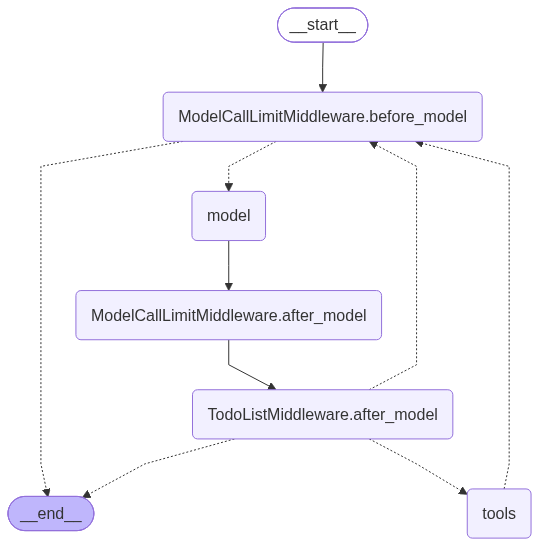

In [7]:
from IPython.display import Image, display
try:
    png = agent.get_graph().draw_mermaid_png()
    (root / "outputs").mkdir(exist_ok=True)
    (root / "outputs" / "agent_graph.png").write_bytes(png)
    display(Image(png))
except Exception as e:
    print("PNG render unavailable (", e, ") - mermaid source above is the graph.")

## Stage 4 — Live multi-agent run

Each step shows which **specialist** the orchestrator delegated to, the task it wrote, and
the report that came back. The specialists' internal SQL/Cypher/Python stays in their own
contexts.

In [8]:
from mas.orchestrator import run, format_trace
result = run("What is the latest alert on BFP-A? Plot the bearing temperature "
             "across that alert window and explain what happened.")
print(format_trace(result))


─── step 1: write_todos ───
  todos: [{'status': 'in_progress', 'content': 'Query graph_agent for the latest alert on BFP-A (bfpa), including timestamp window, tag, severity, threshold, peak, and related maintenance/work orders'}, {'content': 'Query sql_agent to fetch bearing temperature telemetry (and correlated tags if relevant) on bfpa during the alert window', 'status': 'pending'}, {'status': 'pending', 'content': 'Use coder_agent to generate the bearing temperature plot and compute telemetry statistics'}, {'content': 'Synthesize findings and write detailed final explanation of what happened', 'status': 'pending'}]
  → Updated todo list to [{'content': 'Query graph_agent for the latest alert on BFP-A (bfpa), including timestamp window, tag, severity, threshold, peak, and related maintenance/work orders', 'status': 'in_progress'}, {'content': 'Query sql_agent to fetch bearing temperature telemetry (and correlated tags if relevant) on bfpa during the alert window', 'status': 'pendin

## Stage 5 — Context isolation (why 3 + 1 beats one big agent)

The orchestrator's context holds only its delegations and the specialists' reports. Every
low-level tool call — each SQL string, each digest, each stdout dump — stayed inside a
specialist and was discarded. Artifact count is a proxy for that hidden work.

In [9]:
from langchain_core.messages import AIMessage
from mas.orchestrator.trace import content_text

msgs = result["messages"]
chars = sum(len(content_text(m.content)) for m in msgs)
calls = [c["name"] for m in msgs if isinstance(m, AIMessage) for c in (m.tool_calls or [])]
bb = result.get("blackboard") or {}

print("ORCHESTRATOR CONTEXT")
print("  messages           :", len(msgs))
print("  total chars        :", chars)
print("  delegations        :", calls)
print("  artifacts produced :", len(bb), "->", list(bb))
print("\n  each artifact = >=1 low-level tool call that never entered this context")

ORCHESTRATOR CONTEXT
  messages           : 16
  total chars        : 19778
  delegations        : ['write_todos', 'graph_agent', 'write_todos', 'sql_agent', 'write_todos', 'coder_agent', 'write_todos']
  artifacts produced : 7 -> ['g1', 'g2', 'g3', 'g4', 't5', 't6', 'f7']

  each artifact = >=1 low-level tool call that never entered this context


## Stage 6 — Figures produced

Payloads (DataFrames, PNGs) live in an **out-of-band store**, never in graph state and
never in a prompt — graph state carries only the lightweight digest index.

f7: outputs\figures\analysis_7.png


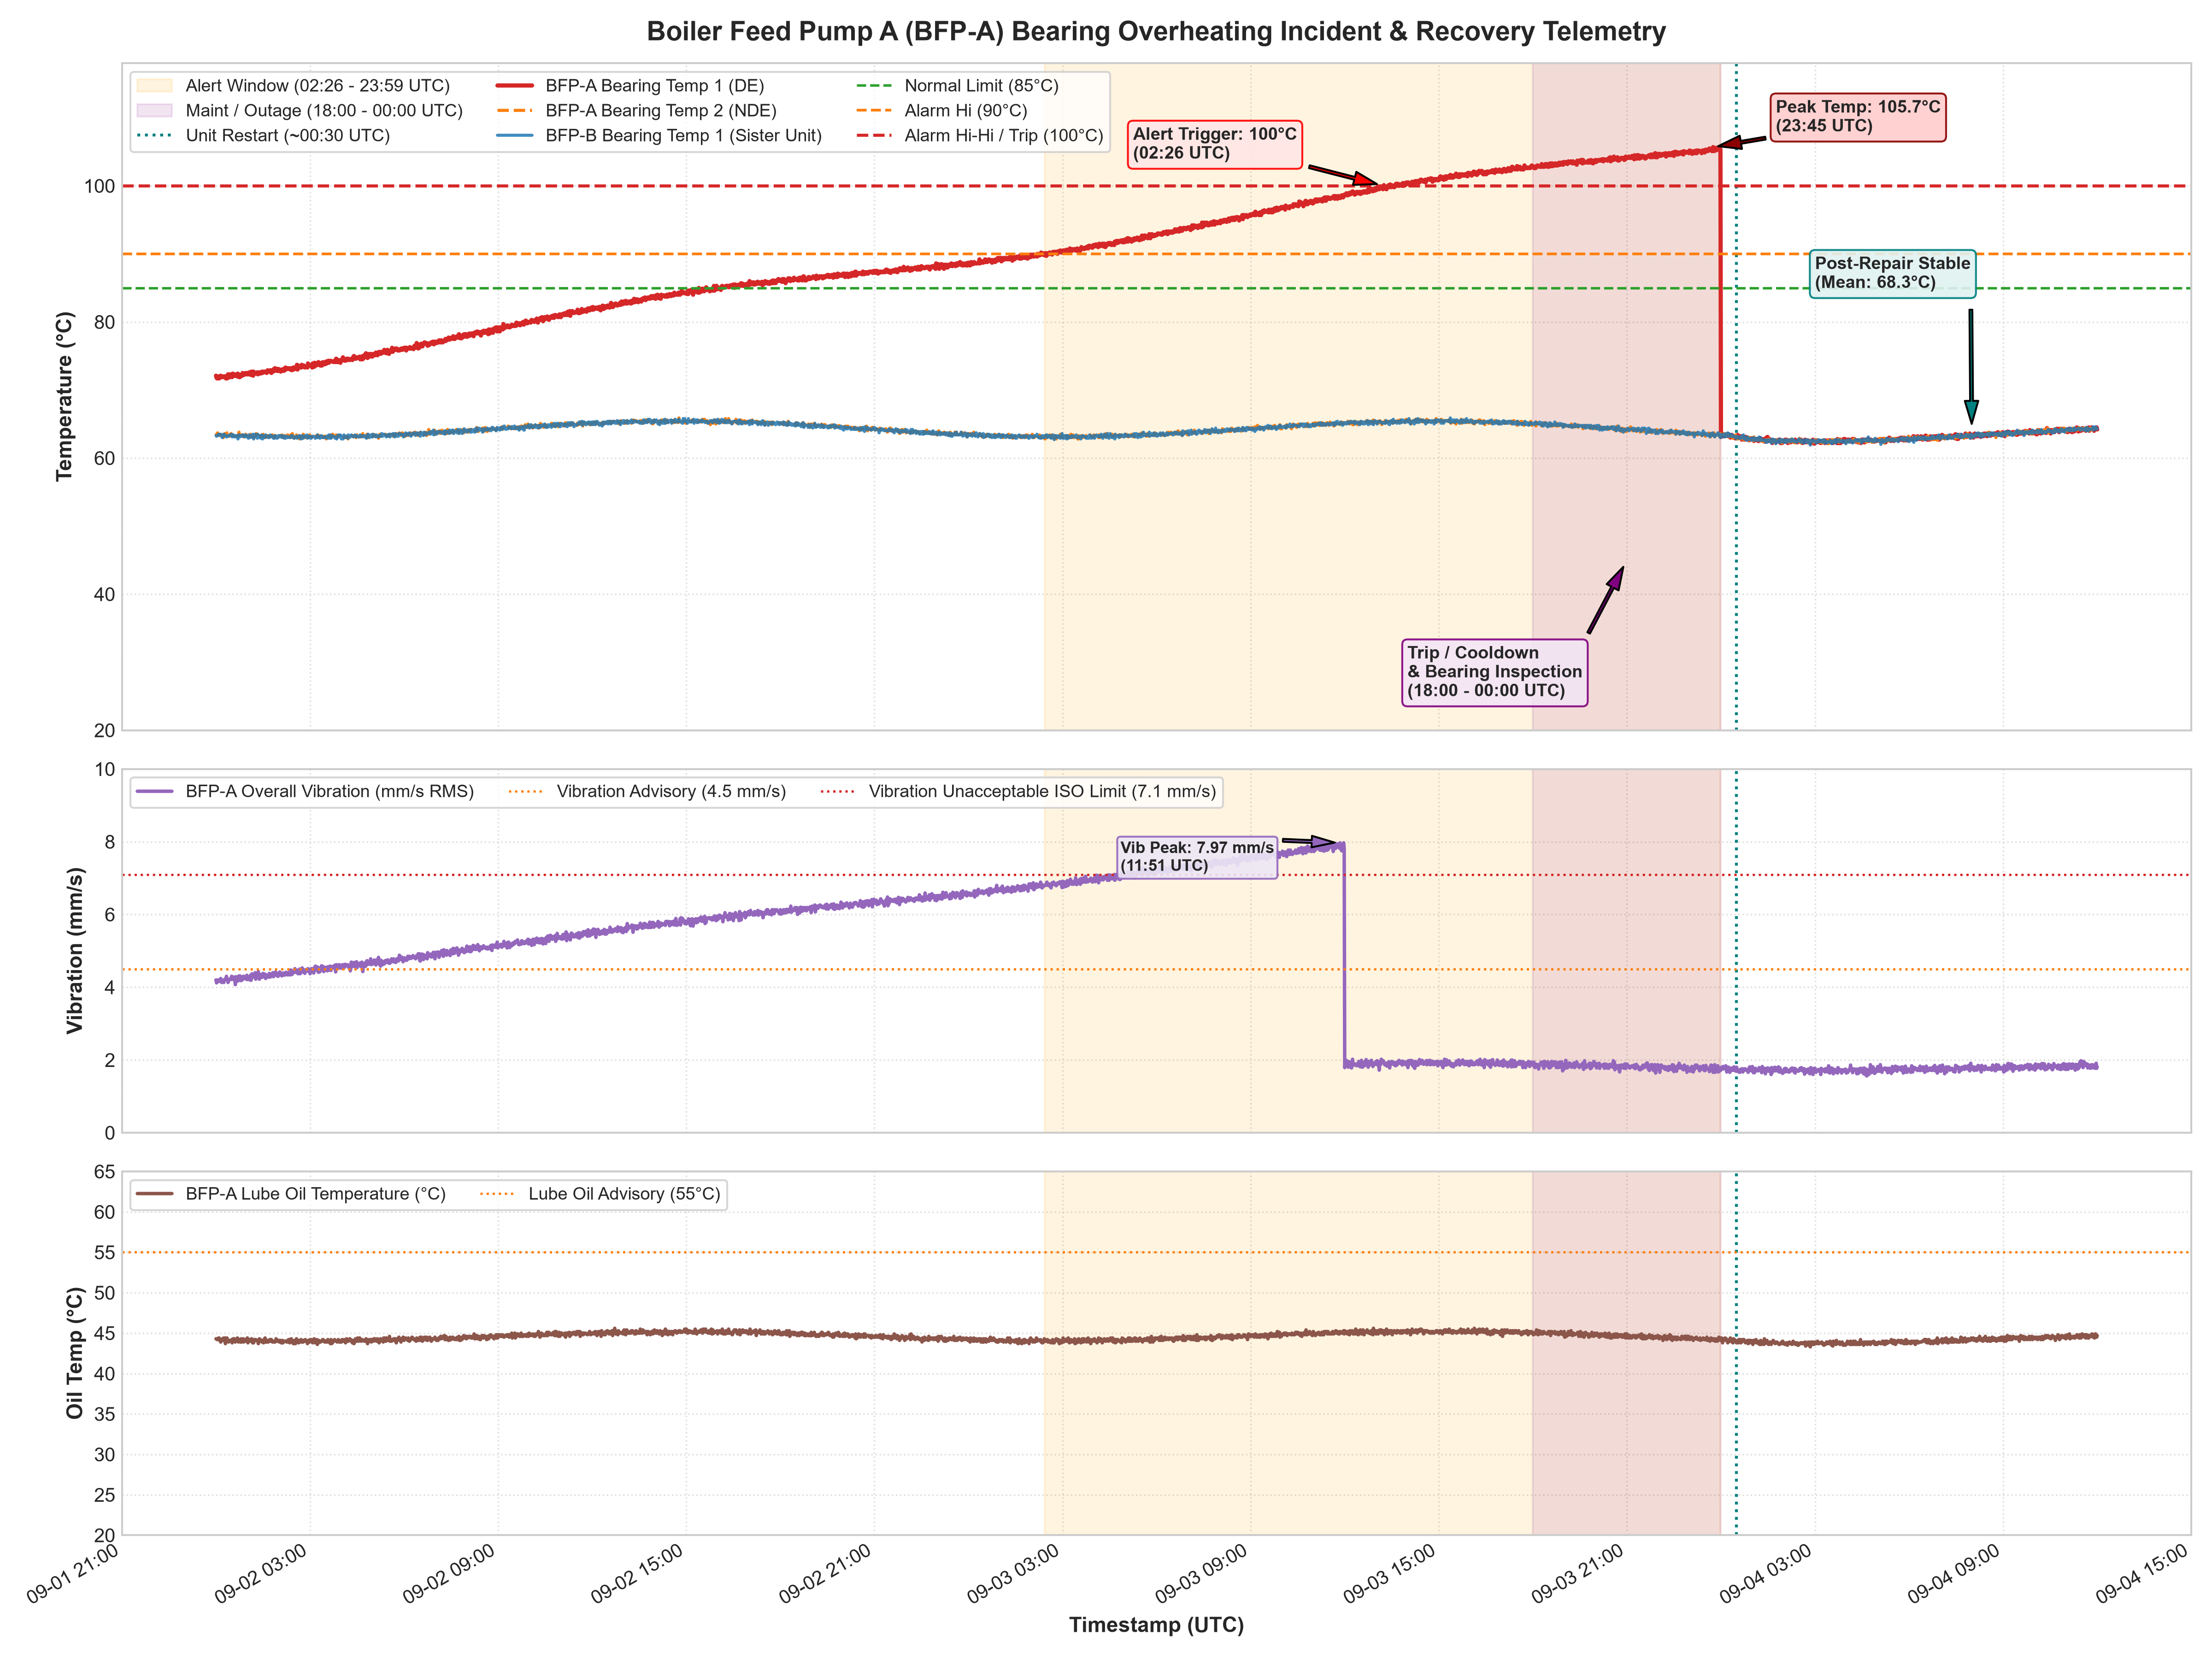

figures: ['outputs\\figures\\analysis_7.png']


In [10]:
from IPython.display import Image, display
from mas.memory import store
from mas.memory.artifacts import FigureArtifact

figs = store.of_kind(FigureArtifact)   # payloads live out-of-band, not in graph state
for fid, f in figs:
    print(f"{fid}: {f.png_path}")
    display(Image(f.png_path))
print("figures:", [f.png_path for _, f in figs] or "(none)")

## Try it yourself

Edit **`MY_QUERY`** and re-run. Ask something open-ended — the orchestrator will plan,
delegate across the team, and explain.

In [11]:
MY_QUERY = "Compare BFP-A and BFP-B bearing_temp_1 over the last 7 days and tell me which ran hotter and why."

my_result = run(MY_QUERY)
print(format_trace(my_result))


─── step 1: write_todos ───
  todos: [{'content': 'Query graph_agent for bearing_temp_1 alarm thresholds, recent alerts, and maintenance history on bfpa and bfpb', 'status': 'in_progress'}, {'content': 'Query sql_agent for bearing_temp_1 summary statistics and time series data on bfpa and bfpb (2026-08-31 to 2026-09-07)', 'status': 'pending'}, {'content': 'Investigate correlated tags (lube oil, vibration, motor load, cooling) to explain why one ran hotter', 'status': 'pending'}, {'content': 'Perform comparative analysis and synthesize final answer', 'status': 'pending'}]
  → Updated todo list to [{'content': 'Query graph_agent for bearing_temp_1 alarm thresholds, recent alerts, and maintenance history on bfpa and bfpb', 'status': 'in_progress'}, {'content': 'Query sql_agent for bearing_temp_1 summary statistics and time series data on bfpa and bfpb (2026-08-31 to 2026-09-07)', 'status': 'pending'}, {'content': 'Investigate correlated tags (lube oil, vibration, motor load, cooling) to 

## Where this is going

Done: the data layer, the safety validators, artifacts/digests, the expert tool set, and the
**orchestrator + 3 specialist agents** running against live Postgres + Neo4j with isolated
contexts. Next: multi-turn sessions via a checkpointer (`thread_id`), a multimodal
self-check on generated figures, and re-baselining the golden eval against the team.